# Inflation–Labor Pressure → U.S. Treasury Bill Yield Changes

**Executable, falsifiable historical money-market research | 2026-10-28**

Data are a fixed 2009 compilation, not point-in-time releases; no equity or total-return alpha claim.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
from IPython.display import display, Image
from run_analysis import ROOT, load_raw, build_panel, walk_forward, scores, paired_block_bootstrap, compute
pd.set_option('display.max_columns', 20)
print('Study root:',ROOT)

Study root: /mnt/data/s2a_money_market_20261028


## 01. Abstract

**Question.** Does a predeclared lagged inflation–labor-slack pressure signal forecast the next-quarter change in the U.S. 3-month Treasury-bill secondary-market rate, beyond standard rate and macroeconomic controls? This historical **1959Q1–2009Q3** market-rate study uses the 203-quarter `statsmodels` macrodata fixed snapshot compiled from FRED/BLS data accessed on **2009-12-15**. In 115 purged expanding-window forecasts (1980Q4–2009Q2), the full model RMSE is **0.808 percentage points**, versus **0.817** for the macro control and **0.738** for the historical mean. The marginal control-relative improvement is **+0.009 pp**; this does not beat the mean or zero-change baseline. **Verdict: retrospective short-rate macro pilot, NOT PIT and NOT investable alpha.**

In [2]:
# Reproduce all 1,000 block placebos, 2,000 bootstraps and 1,000 weight variants
metrics = compute()
print(json.dumps({k:metrics[k] for k in ['dataset_rows','oos_n','main_gain_rmse_pp','placebo_upper_tail_fraction','bootstrap_ci_95']},indent=2))

{
  "dataset_rows": 203,
  "oos_n": 115,
  "main_gain_rmse_pp": 0.009320636680685501,
  "placebo_upper_tail_fraction": 0.057942057942057944,
  "bootstrap_ci_95": [
    -0.03553153338009717,
    0.04966929784348751
  ]
}


In [3]:
print('Predeclared evidence level:', 'NOT PIT / NOT INVESTABLE ALPHA' if not metrics['source_vintage_pit_verified'] else 'REVIEW REQUIRED')

Predeclared evidence level: NOT PIT / NOT INVESTABLE ALPHA


## 02. Research Design & Hypotheses

**Primary falsifiable question:** At quarter-end t, does the known-at-t−1 CPI-inflation-minus-unemployment-change pressure score predict Δr_{t+1}=r_{t+1}−r_t beyond a prespecified macro Ridge model? **H1 (direction):** more inflation pressure raises next-quarter bill yields; **H2 (increment):** adding the score lowers purged expanding OOS RMSE relative to a rate-level/momentum/unemployment/GDP control; **H3 (robustness):** the gain survives block-aware nulls, decade exclusions, lag/horizon changes and pressure-weight perturbations. **Null:** no incremental predictive information beyond controls. Failure criterion: full-model RMSE not below both control and simple mean/zero-change, or unstable confidence intervals. **Counterthesis:** market yields incorporate inflation and policy expectations immediately, while revisions and structural monetary regimes swamp a stale quarterly signal. Mishkin (1991, https://www.nber.org/papers/w3632) finds long-run Fisher-effect evidence but not a universal short-run Fisher effect; the short-horizon H1 is therefore genuinely contestable.

In [4]:
print('H1 direction, H2 incremental RMSE, H3 robustness are falsifiable.')
print('Null: no incremental forecast value. Decision: compare all baselines and uncertainty.')

H1 direction, H2 incremental RMSE, H3 robustness are falsifiable.
Null: no incremental forecast value. Decision: compare all baselines and uncertainty.


In [5]:
print('Primary horizon=1Q; minimum training=80; Ridge alpha=12; purge=1Q after target maturity.')

Primary horizon=1Q; minimum training=80; Ridge alpha=12; purge=1Q after target maturity.


## 03. Industry Context

**Market, not NAICS industry:** U.S. Treasury bills are short-term marketable federal obligations sold at discount; this is a **Treasury money-market** study, distinct from industrial production and equity-price studies. The Treasury is the issuer; dealers intermediate primary/secondary markets; banks and money-market funds are potential users. These channels are qualitative and **not firm-level measured exposure**. TreasuryDirect describes bills and their discount mechanism (https://www.treasurydirect.gov/research-center/history-of-marketable-securities/bills/t-bills-faqs/). **Historical 1959–2009 market size/growth: UNKNOWN** from the frozen dataset; current issuance statistics would be anachronistic.

In [6]:
exposure = pd.read_csv(ROOT/'data/company_exposure_map.csv')
display(exposure)
print('Historical market-size time series: UNKNOWN; do not extrapolate current issuance.')

,participant,channel,observed_exposure_weight,as_of_date,evidence_level
0,U.S. Treasury,issuer of discount bills,UNKNOWN,UNKNOWN,conceptual only
1,Primary dealers,auction and secondary-market intermediation,UNKNOWN,UNKNOWN,conceptual only
2,Money-market funds,short-duration cash investment,UNKNOWN,UNKNOWN,conceptual only
3,Commercial banks,liquidity and rate transmission,UNKNOWN,UNKNOWN,conceptual only


Historical market-size time series: UNKNOWN; do not extrapolate current issuance.


## 04. Data & Source Integrity

**Source hierarchy:** A = original government series and Treasury definitions; B = a reproducible public-package frozen compilation; C = secondary contextual commentary (none used in model). Raw data are frozen as `data/macrodata_statsmodels_2009_snapshot.csv`; 203 quarters, 14 source columns, 1959Q1–2009Q3. Source register records original URLs, publishers, units, original publication date **UNKNOWN**, package access **2009-12-15**, local collection **2026-10-28**, observed period and revision caveats. Variables: `tbilrate` (quarterly average 3m bill rate in annualized percent), `infl` (annualized log CPI change), `unemp` (percent), `realgdp` (chained 2005-dollar billions). Original package provenance: https://github.com/statsmodels/statsmodels/blob/main/statsmodels/datasets/macrodata/data.py. The frozen package CSV is reproducible, but the original 2009 FRED files and per-quarter releases were not reconstructed.

In [7]:
raw = load_raw()
display(raw[['period','tbilrate','infl','unemp','realgdp']].iloc[[0,1,-2,-1]])
print('Source rows, columns, missing cells:', raw.shape, int(raw.isna().sum().sum()))

,period,tbilrate,infl,unemp,realgdp
0,1959Q1,2.82,0.00,5.8,2710.349
1,1959Q2,3.08,2.34,5.1,2778.801
201,2009Q2,0.18,3.37,9.2,12901.504
202,2009Q3,0.12,3.56,9.6,12990.341


Source rows, columns, missing cells: (203, 15) 0


In [8]:
register=pd.read_csv(ROOT/'data/source_register.csv')
display(register[['source_id','grade','publisher','original_publication_date','revision_vintage_status']])

,source_id,grade,publisher,original_publication_date,revision_vintage_status
0,SM_MACRO,B,statsmodels / Skipper Seabold,UNKNOWN,Fixed package snapshot / historical vintages U...
1,FED_H15,A,Federal Reserve Board,UNKNOWN,Historical releases not reconstructed
2,BLS_CPI,A,Bureau of Labor Statistics,UNKNOWN,Historical releases not reconstructed
3,BLS_UNEMP,A,Bureau of Labor Statistics,UNKNOWN,Historical releases not reconstructed
4,BEA_GDP,A,Bureau of Economic Analysis,UNKNOWN,Historical releases not reconstructed
5,TREASURY,A,U.S. Department of the Treasury,UNKNOWN,Current web description not 1959-2009 historic...
6,MISHKIN_1991,B,National Bureau of Economic Research,1991-02,Academic historical paper


In [9]:
import hashlib
assert hashlib.sha256((ROOT/'data/macrodata_statsmodels_2009_snapshot.csv').read_bytes()).hexdigest()==metrics['raw_sha256']
print('Frozen input SHA-256:',metrics['raw_sha256'])

Frozen input SHA-256: d93c0d3a7a77ef83c3af14e46032bb1d02ae3a512b22ab94159a8ca226fcf708


## 05. Point-in-Time Availability

**Observation lag:** at the end of quarter t, macro features use only quarter t−1 or earlier; no contemporaneous CPI/unemployment/GDP values enter the signal. The next-quarter yield change Δr_{t+1} is measured after t. Training uses only examples s with s+h ≤ t−1, leaving one complete quarter as a purge buffer beyond the target horizon. **Critical limitation:** these are 2009-fixed retrospectively revised source values; a fixed observation lag does not reconstruct historical release vintages, so true formation-time availability remains **UNKNOWN / NOT PIT**. Actual monthly release timestamps and past revisions need ALFRED/archived H.15/BLS/BEA downloads before PIT claims.

In [10]:
panel=build_panel(raw)
assert all(panel.origin_idx >  panel.origin_idx-panel.lag)
assert (panel.input_period != panel.origin).all()
display(panel[['input_period','origin','target_period','factor','target']].head(6))

,input_period,origin,target_period,factor,target
0,1960Q2,1960Q3,1960Q4,0.14,-0.07
1,1960Q3,1960Q4,1961Q1,2.50,0.08
2,1960Q4,1961Q1,1961Q2,0.86,-0.08
3,1961Q1,1961Q2,1961Q3,-0.65,0.03
4,1961Q2,1961Q3,1961Q4,1.37,0.28
5,1961Q3,1961Q4,1962Q1,0.90,0.13


In [11]:
oos=walk_forward(panel)
assert (oos.max_train_target_idx<=oos.origin_idx-1).all()
print('Strict target-release purge passed on',len(oos),'OOS origins; first',oos.origin.iloc[0])

Strict target-release purge passed on 115 OOS origins; first 1980Q4


## 06. Factor Construction

Let π_{t−1}=400·log(CPI_{t−1}/CPI_{t−2}) (annualized log percentage points, from frozen `infl`); Δu_{t−1}=u_{t−1}−u_{t−2} (percentage points). **Predeclared score** F_t = π_{t−1} − 0.5·Δu_{t−1}. The 0.5 coefficient is a fixed economic sensitivity assumption, **not** a fitted historical exposure. Target Y_t=r_{t+1}−r_t in annualized yield percentage points; all model standardization uses only the current training window. We vary the unemployment weight from 0.1 to 1.0 in 1,000 exploratory perturbations. The formula is an inflation/slack proxy, not a tradable spread or security return.

In [12]:
print('Factor = annualized lagged CPI inflation - 0.5 × lagged change in unemployment.')
print('Target = next-quarter minus current-quarter annualized 3m T-bill rate.')
display(panel[['inflation_l','unemployment_change','factor','target']].describe().round(3))

Factor = annualized lagged CPI inflation - 0.5 × lagged change in unemployment.
Target = next-quarter minus current-quarter annualized 3m T-bill rate.


,inflation_l,unemployment_change,factor,target
count,196.000,196.000,196.000,196.000
mean,4.028,0.015,4.021,-0.011
std,3.282,0.333,3.286,0.878
min,-8.790,-0.900,-9.240,-5.850
25%,2.275,-0.200,2.282,-0.267
50%,3.275,-0.050,3.375,0.035
75%,5.058,0.100,4.962,0.373
max,14.620,1.600,14.620,4.410


In [13]:
assert np.allclose(panel.factor,panel.inflation_l-0.5*panel.unemployment_change)
print('Fixed weight identity verified for all',len(panel),'formation rows')

Fixed weight identity verified for all 196 formation rows


## 07. Exposure & Transmission

Proposed mechanism: inflationary pressure can raise expected policy rates, pushing 3m Treasury bill yields higher; rising unemployment may moderate policy expectations. The fixed pressure score is applied to the **market-wide bill yield**, with no arbitrary issuer-specific return exposures. `data/company_exposure_map.csv` lists the Treasury, primary dealers, money-market funds and banks as **conceptual, unweighted** participants with `UNKNOWN` company weights and dates. There is no company leave-one-out test because no company panel exists; instead we report leave-one-decade-out robustness. No inference about bank EPS, fund NAV or total returns is possible.

In [14]:
display(exposure[['participant','channel','observed_exposure_weight']])
print('Firm-level weights, filing dates, total returns: unavailable; leave-one-company-out: N/A')

,participant,channel,observed_exposure_weight
0,U.S. Treasury,issuer of discount bills,UNKNOWN
1,Primary dealers,auction and secondary-market intermediation,UNKNOWN
2,Money-market funds,short-duration cash investment,UNKNOWN
3,Commercial banks,liquidity and rate transmission,UNKNOWN


Firm-level weights, filing dates, total returns: unavailable; leave-one-company-out: N/A


## 08. Outcomes & Baselines

**Same origins and targets for every model.** Baselines: historical mean change; zero-change yield persistence; naive prior-quarter rate momentum; AR Ridge with lagged rate and momentum; multivariate control Ridge with lagged rate, rate momentum, unemployment and 4-quarter real-GDP growth; pressure-only Ridge; full control+F Ridge. Ridge α=12 fixed ex ante (not tuned on OOS). Expanding training requires ≥80 eligible observations and target-release purge. Report RMSE, MAE and directional accuracy. No IC/spread is reported because this is a single market-rate time series, not a security cross-section.

In [15]:
scorecard=scores(oos);display(scorecard.round(4))

,model,n,rmse,mae,sign_accuracy
0,mean,115,0.7381,0.4595,0.5043
1,persistence,115,0.7229,0.4538,0.0087
2,momentum,115,1.0865,0.6194,0.6000
3,ar_ridge,115,0.8029,0.5252,0.4522
4,control,115,0.8173,0.4967,0.4783
5,factor_only,115,0.7395,0.4609,0.4435
6,full,115,0.8080,0.4965,0.5304


In [16]:
print('Training counts:',oos.n_train.min(),oos.n_train.max(),'and all models share',len(oos),'origins')
print('Primary baseline names:',list(scorecard.model))

Training counts: 80 194 and all models share 115 origins
Primary baseline names: ['mean', 'persistence', 'momentum', 'ar_ridge', 'control', 'factor_only', 'full']


## 09. Empirical Findings

**Primary 115 purged expanding-window forecasts (1980Q4–2009Q2).** RMSE (yield percentage points): mean **0.7381**, zero-change **0.7229**, momentum **1.0865**, AR Ridge **0.8029**, macro control **0.8173**, pressure-only **0.7395**, full **0.8080**. Control−full improvement is **+0.0093 pp**. The full model fails to outperform the simple mean and zero-change baselines. The full-sample (non-causal, in-sample) Pearson correlation between lagged factor and future yield change is **+0.0316**, a directional check for H1 rather than an OOS validation. All metrics are computed and saved in `results/scorecard.csv`, `results/walk_forward_oos.csv`, and `results/metrics.json`. This is a forecast-error comparison, not an investment profit claim.

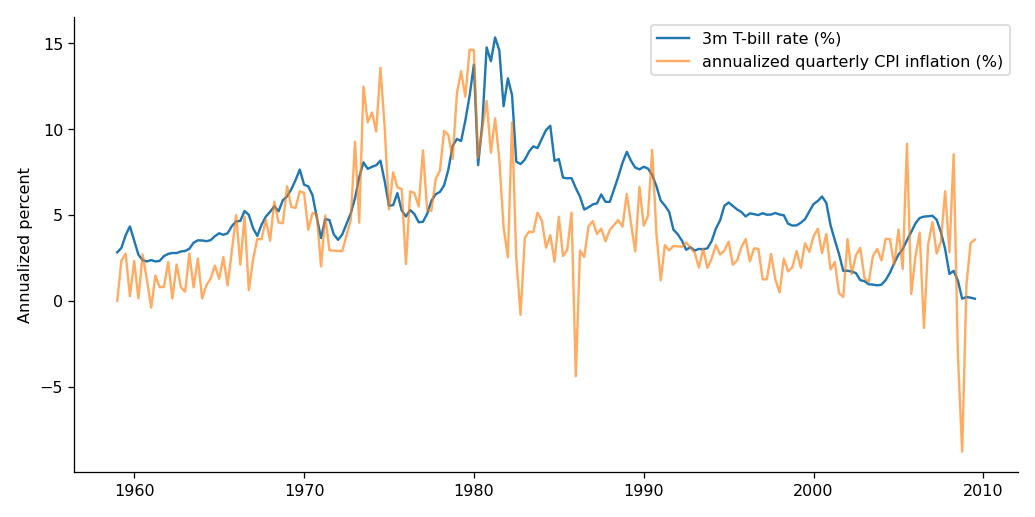

In [17]:
display(Image(filename=str(ROOT/'figures/01_rate_and_inflation.png'),width=760))

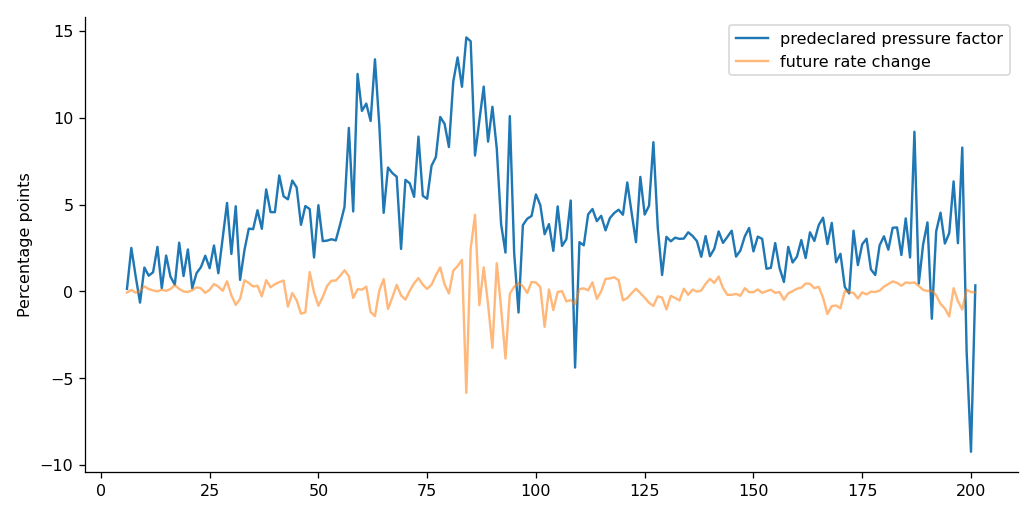

In [18]:
display(Image(filename=str(ROOT/'figures/02_factor_and_target.png'),width=760))

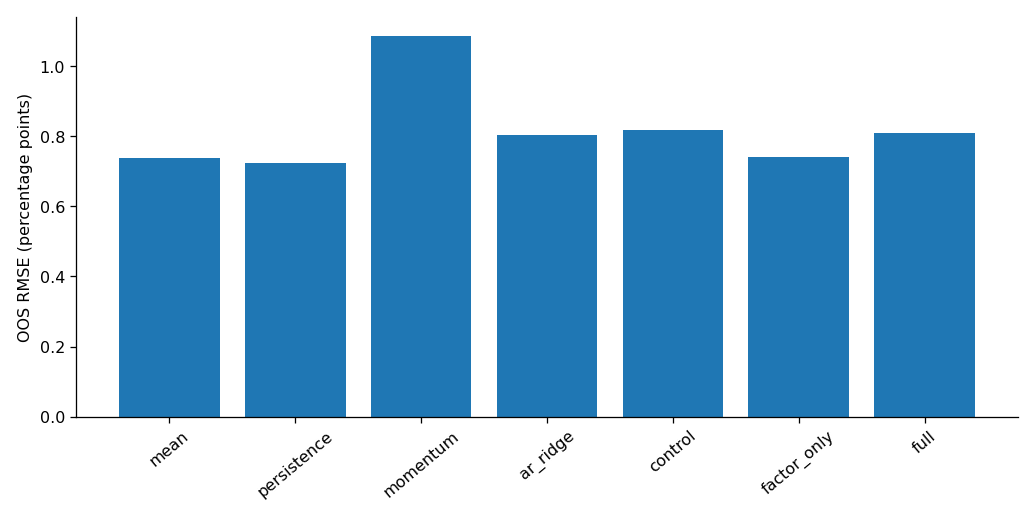

In [19]:
display(Image(filename=str(ROOT/'figures/04_baseline_scorecard.png'),width=760))

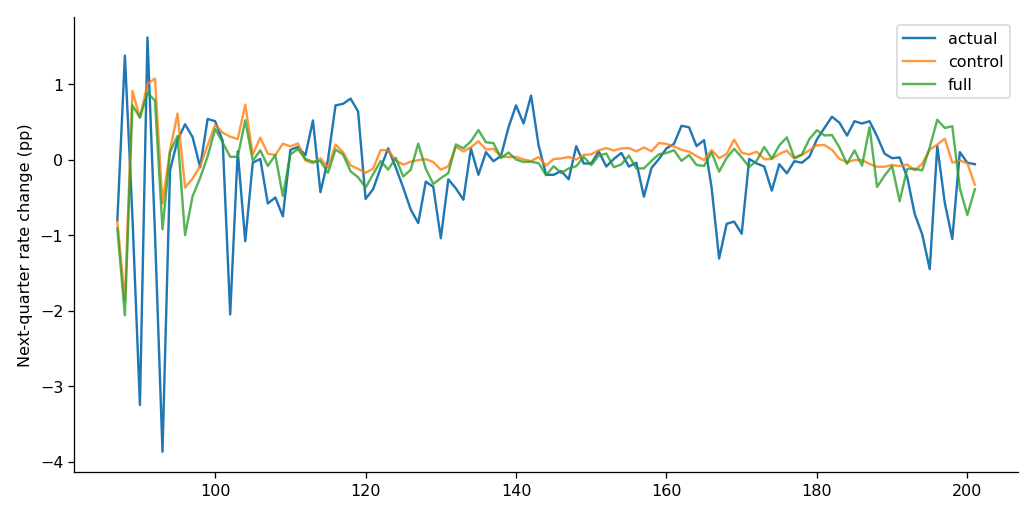

In [20]:
display(Image(filename=str(ROOT/'figures/05_oos_forecasts.png'),width=760))

In [21]:
display(pd.read_csv(ROOT/'results/factor_association.csv'))

,n,pearson_factor_target,spearman_factor_target
0,196,0.031583,0.105699


In [22]:
loss=(oos.control-oos.target)**2-(oos.full-oos.target)**2
print('Paired OOS squared-error difference: mean=',round(float(loss.mean()),6),'positive fraction=',round(float((loss>0).mean()),3))

Paired OOS squared-error difference: mean= 0.015149 positive fraction= 0.47


## 10. Robustness & Placebos

**Block-aware null:** 1,000 re-fitted 8-quarter block-order shuffles of the pressure factor; exploratory upper-tail fraction **0.0579** (not an exact randomization p-value because blocks are not exchangeable under structural change). **Paired uncertainty:** 2,000 circular 8-quarter block bootstrap draws of paired OOS errors; 95% interval for control−full RMSE **[-0.0355, +0.0497] pp**. **Exposure perturbation:** 1,000 fixed-weight variants (0.1–1.0), positive-improvement share **100.0%**. Additional saved ablations isolate inflation, unemployment-change and sign reversal. These are exploratory stress tests, not multiple-testing-corrected discoveries.

In [23]:
placebo=pd.read_csv(ROOT/'results/block_placebo_1000.csv');display(placebo.delta_rmse.describe().to_frame('block placebo'))
print('Exploratory upper-tail fraction:',metrics['placebo_upper_tail_fraction'])

,block placebo
count,1000.000000
mean,-0.004009
std,0.009296
min,-0.060182
25%,-0.007841
50%,-0.003306
75%,-0.000454
max,0.047057


Exploratory upper-tail fraction: 0.057942057942057944


In [24]:
bootstrap=pd.read_csv(ROOT/'results/paired_block_bootstrap_2000.csv');display(bootstrap.delta_rmse.quantile([.025,.5,.975]).to_frame('paired block RMSE improvement'))

,paired block RMSE improvement
0.025,-0.035532
0.500,0.011131
0.975,0.049669


In [25]:
pert=pd.read_csv(ROOT/'results/exposure_perturbation_1000.csv');display(pert[['weight','delta_rmse']].describe())

,weight,delta_rmse
count,1000.000000,1000.000000
mean,0.565884,0.009361
std,0.256079,0.000178
min,0.102674,0.009027
25%,0.350248,0.009213
50%,0.583119,0.009379
75%,0.775003,0.009508
max,0.999872,0.009650


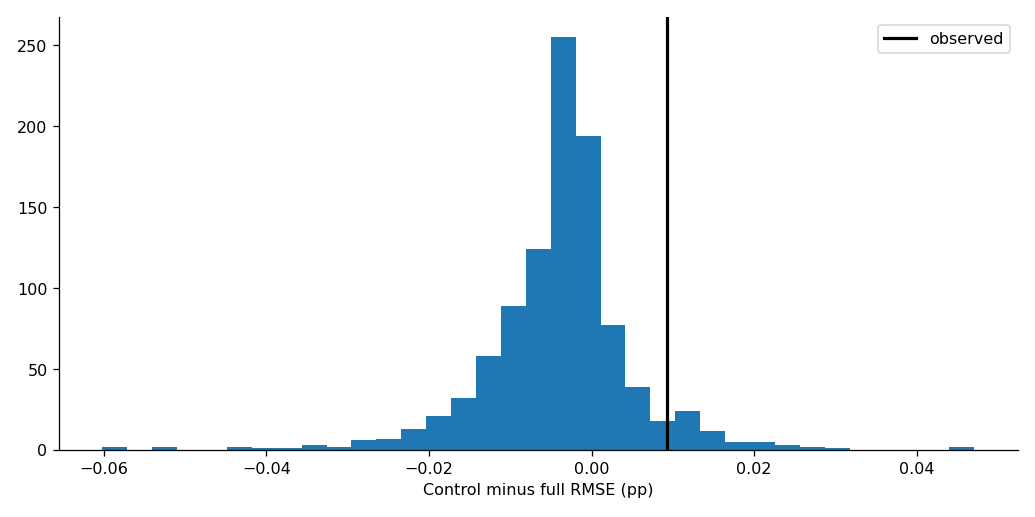

In [26]:
display(Image(filename=str(ROOT/'figures/07_block_placebo.png'),width=700))

## 11. Regime Sensitivity

Regime analysis reports 1980s, 1990s and 2000s, excluding 2008–09, plus leave-one-decade-out evaluation; OOS origin years begin in 1980. The target spans changing monetary-policy frameworks, disinflation, the Great Moderation and the 2008 crisis. Alternative forecast horizons 2Q/3Q and observation lags 2Q are independently re-estimated with the same purge logic. A one-time positive average improvement can be driven by particular rate regimes; do not generalize to the modern post-2009 low-rate or post-2022 tightening environments.

In [27]:
display(pd.read_csv(ROOT/'results/regime_sensitivity.csv'))

,regime,n,delta_rmse,full_rmse,control_rmse
0,1980s,37,0.036214,1.216130,1.252343
1,1990s,40,0.005482,0.379754,0.385236
2,2000s,38,-0.037976,0.619506,0.581531
3,exclude_2008_2009,109,0.022772,0.806646,0.829419
4,exclude_1980s,78,-0.020038,0.510812,0.490774


In [28]:
display(pd.read_csv(ROOT/'results/leave_one_decade_out.csv'))

,omitted_decade,n,delta_rmse,full_rmse,control_rmse
0,1980,78,-0.020038,0.510812,0.490774
1,1990,75,0.010857,0.961290,0.972147
2,2000,77,0.025105,0.886335,0.911441


In [29]:
display(pd.read_csv(ROOT/'results/horizon_lag_robustness.csv'))

,horizon,lag,n,delta_rmse
0,1,2,115,0.006861
1,2,1,113,0.044277
2,3,1,111,0.016298
3,2,2,113,-0.013773


## 12. Bias Audit & Verdict

**Lookahead:** target-release purge and one-quarter macro observation lag applied, but original release vintages are UNKNOWN. **Selection:** the dataset ends in 2009Q3; retrospective topic selection and one predeclared signal with exploratory variants remain risks. **Survivorship:** not applicable to a single market yield; however historical market conventions changed. **Multiple testing:** 1 primary specification; sensitivity tables are exploratory and not family-wise adjusted. **Costs/capacity:** no futures, bill prices, transaction costs, funding or execution tested; yield changes ≠ bill total returns. **Verdict:** at most a retrospective rate-forecast pilot; not PIT, not a verified macro trading strategy, and not equity alpha.

In [30]:
display(pd.read_csv(ROOT/'results/ablations.csv'))
print('Audit: NOT PIT, no securities, no transaction costs, no multiple-testing-adjusted discovery.')

,ablation,n,delta_rmse
0,inflation_only,115,0.008947
1,unemployment_change_only,115,-0.002620
2,opposite_sign,115,0.009321


Audit: NOT PIT, no securities, no transaction costs, no multiple-testing-adjusted discovery.


In [31]:
print('Full versus mean RMSE difference:',round(metrics['rmse']['full']-metrics['rmse']['mean'],5))
print('No investable equity alpha established:',not metrics['equity_alpha_established'])

Full versus mean RMSE difference: 0.0699
No investable equity alpha established: True


## 13. Reproduction

From a clean checkout: `python -m pip install -r requirements.txt`; `OPENBLAS_NUM_THREADS=1 python run_analysis.py`; `OPENBLAS_NUM_THREADS=1 python -m pytest -q tests`; `OPENBLAS_NUM_THREADS=1 jupyter nbconvert --to notebook --execute research.ipynb --output /tmp/money_market_reexecuted.ipynb --ExecutePreprocessor.timeout=900`. From repository root also run `python scripts/validate_studies.py`. Raw data and derived panels are frozen; all random draws use explicit seeds. Numerical results and diagnostic figures are committed, and the notebook regenerates the analysis when executed. Python package version, output hashes and logs are recorded in `logs/`.

In [32]:
print('Saved result tables:',len(list((ROOT/'results').glob('*.csv'))),'Saved figures:',len(list((ROOT/'figures').glob('*.png'))))
assert len(list((ROOT/'figures').glob('*.png')))>=3

Saved result tables: 10 Saved figures: 10


In [33]:
assert len(pd.read_csv(ROOT/'results/block_placebo_1000.csv'))==1000
assert len(pd.read_csv(ROOT/'results/paired_block_bootstrap_2000.csv'))==2000
print('Required Monte Carlo draw counts verified.')

Required Monte Carlo draw counts verified.


## 14. Next-Stage Protocol

To move toward a valid prospective test: (1) obtain ALFRED CPI/UNRATE/GDP vintages and archived H.15 observation/release dates; (2) reconstruct exact formation-time information sets and benchmark revisions; (3) replace quarterly historical data with monthly/daily real-time policy expectations, yield curves and auction calendars; (4) evaluate actual bill or futures **total returns** net of costs and funding against duration-neutral benchmarks; (5) preregister specifications, reserve a post-2009 untouched holdout and correct for multiple testing. No alpha claim until these steps are complete.

In [34]:
print('Next: archival ALFRED/H15 releases, 2009+ holdout, instrument-level total returns, execution and cost model.')

Next: archival ALFRED/H15 releases, 2009+ holdout, instrument-level total returns, execution and cost model.


## 15. Sources & Artifacts

**A (official):** Federal Reserve H.15/TB3MS https://fred.stlouisfed.org/series/TB3MS; BLS CPI https://fred.stlouisfed.org/series/CPIAUCSL; BLS unemployment https://fred.stlouisfed.org/series/UNRATE; BEA GDP https://fred.stlouisfed.org/series/GDPC1; Treasury bills https://www.treasurydirect.gov/research-center/history-of-marketable-securities/bills/t-bills-faqs/. **B (prior theory):** Mishkin (1991), https://www.nber.org/papers/w3632. **B (frozen compilation):** statsmodels macrodata https://github.com/statsmodels/statsmodels/blob/main/statsmodels/datasets/macrodata/macrodata.csv (original FRED/BLS access 2009-12-15; package source notes https://github.com/statsmodels/statsmodels/blob/main/statsmodels/datasets/macrodata/data.py). **Artifacts:** `data/source_register.csv`, `data/provenance_audit.md`, frozen raw/derived CSV, `results/` computed tables and diagnostics, `figures/` 10 plots, `tests/`, `logs/`. Original publication dates and per-quarter vintages remain UNKNOWN.

In [35]:
display(register[['source_id','grade','original_url','observed_start','observed_end']])

,source_id,grade,original_url,observed_start,observed_end
0,SM_MACRO,B,https://github.com/statsmodels/statsmodels/blo...,1959Q1,2009Q3
1,FED_H15,A,https://fred.stlouisfed.org/series/TB3MS,1959Q1,2009Q3
2,BLS_CPI,A,https://fred.stlouisfed.org/series/CPIAUCSL,1959Q1,2009Q3
3,BLS_UNEMP,A,https://fred.stlouisfed.org/series/UNRATE,1959Q1,2009Q3
4,BEA_GDP,A,https://fred.stlouisfed.org/series/GDPC1,1959Q1,2009Q3
5,TREASURY,A,https://www.treasurydirect.gov/research-center...,NOT_APPLICABLE,NOT_APPLICABLE
6,MISHKIN_1991,B,https://www.nber.org/papers/w3632,NOT_APPLICABLE,NOT_APPLICABLE


In [36]:
print('Final verdict: retrospective money-market rate forecast pilot; not PIT; not investable alpha.')

Final verdict: retrospective money-market rate forecast pilot; not PIT; not investable alpha.
